# ELEC0447: Power System Frequency Dynamics & Primary Control Simulation
*Interactive dynamic simulation of synchronous machine inertia, speed droop, load damping, and PV curtailment.*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/bcornelusse/ELEC0447-analysis-power-systems/blob/master/Lectures/frequency_control/frequency_control_simulation.ipynb)

---

### Mathematical Model

This notebook simulates the coupled frequency and power dynamics of a synchronous machine-dominated power system:

1. **Rotor Motion & Inertia (Swing Equation):**
   $$\frac{df}{dt} = \frac{1}{J} \left( \frac{p_m + p_{pv} - p_e}{4\pi^2 f} - D_g (f - f_N) \right)$$
   where $J$ [$\text{kg}\cdot\text{m}^2$] is the equivalent moment of inertia, $f_N = 50\text{ Hz}$ is the nominal frequency, and $D_g$ is mechanical damping.

2. **Turbine-Governor Dynamics with Speed Droop ($\sigma$):**
   $$T_{sm} \frac{dp_m}{dt} = P^o - p_m - \frac{P_{\max}}{\sigma} \left( \frac{f - f_N}{f_N} \right)$$
   subject to generator capability limits $P_{\min} \le p_m \le P_{\max}$, where $T_{sm}$ is the servomotor time constant and $\sigma$ is the dimensionless speed droop (typically $4\% - 6\%$).

3. **Frequency-Sensitive Load Self-Regulation (Damping $D_l$):**
   $$p_e(f) = P_e^o \left( 1 + D_l (f - f_N) \right)$$

4. **Renewable Injection & Overfrequency Curtailment (LFSM-O):**
   For $f > 50.5\text{ Hz}$, PV inverters curtail power with a defined droop down to $52.0\text{ Hz}$.


## 1. Utility Functions for Plotting
A clean two-pane visualization:
- **Upper pane:** System frequency $f(t)$ [Hz], highlighting the nominal $50.0\text{ Hz}$ line, the $\pm 0.2\text{ Hz}$ normal operating band, the frequency Nadir, and the steady-state frequency.
- **Lower pane:** Active power balance [MW] showing mechanical power $p_m(t)$, load $p_e(t)$, and solar PV $p_{pv}(t)$.


In [5]:
import numpy as np
import matplotlib.pyplot as plt

plt.style.use('bmh')

class FrequencyPlotter:
    # Plots frequency and active power trajectories over time.
    # Accepts direct array tuples (t, f, pm, pe, ppv, ppv_max) or reads from a file.
    def __init__(self, data=None, file_name="frequency.txt"):
        self.data = data
        self.file_name = file_name

    def plot(self, title_suffix=""):
        if self.data is not None:
            t, f, pm, pe, ppv, ppv_max = self.data
        else:
            t, f, pm, pe, ppv, ppv_max = np.loadtxt(self.file_name, unpack=True)

        fig, (ax_f, ax_p) = plt.subplots(2, 1, figsize=(11, 6.5), sharex=True)

        # -------------------------------------------------------------
        # Upper Pane: Frequency
        # -------------------------------------------------------------
        ax_f.plot(t, f, color='#1f77b4', lw=2.2, label=r'Frequency $f(t)$')
        ax_f.axhline(50.0, color='gray', linestyle='--', lw=1.2, alpha=0.7, label=r'Nominal ($50.0$ Hz)')
        ax_f.axhline(49.8, color='orange', linestyle=':', lw=1.2, alpha=0.7, label=r'FCR Band ($\pm 0.2$ Hz)')
        ax_f.axhline(50.2, color='orange', linestyle=':', lw=1.2, alpha=0.7)

        f_min = float(np.min(f))
        t_nadir = float(t[np.argmin(f)])
        f_end = float(f[-1])

        # Annotate final steady-state frequency
        ax_f.annotate(f"Final: {f_end:.2f} Hz", 
                      xy=(t[-1], f_end), 
                      xytext=(t[-1] - 3.8, f_end + (0.15 if f_end < 50 else -0.30)),
                      arrowprops=dict(arrowstyle="->", color='#1f77b4', lw=1.2),
                      fontsize=9, weight='bold',
                      bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="#1f77b4", alpha=0.9))

        # Annotate nadir if distinct from final value
        if abs(f_min - f_end) > 0.05 and t_nadir < t[-1] - 0.5:
            ax_f.annotate(f"Nadir: {f_min:.2f} Hz", 
                          xy=(t_nadir, f_min), 
                          xytext=(t_nadir + 1.0, f_min - 0.25),
                          arrowprops=dict(arrowstyle="->", color='#d62728', lw=1.2),
                          fontsize=9, color='#d62728', weight='bold',
                          bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="#d62728", alpha=0.9))

        ax_f.set_ylabel('Frequency [Hz]', fontsize=11)
        ax_f.set_title(f'System Frequency Dynamic Response {title_suffix}', fontsize=12, weight='bold')
        ax_f.legend(loc='lower left', fontsize=9, framealpha=0.9)
        ax_f.grid(True, alpha=0.4)

        # -------------------------------------------------------------
        # Lower Pane: Powers
        # -------------------------------------------------------------
        ax_p.plot(t, pm * 1e-6, color='#0066b4', lw=2.2, label=r'Mechanical Power $p_m$')
        ax_p.plot(t, pe * 1e-6, color='#d12239', lw=2.2, label=r'Electrical Load $p_e$ (with damping)')
        if np.max(ppv_max) > 0:
            ax_p.plot(t, ppv * 1e-6, color='#2ca02c', lw=2.0, label=r'Actual PV Generation $p_{pv}$')
            ax_p.plot(t, ppv_max * 1e-6, color='#2ca02c', lw=1.5, linestyle=':', label=r'Available PV $p_{pv}^{\max}$')

        ax_p.set_xlabel('Time [s]', fontsize=11)
        ax_p.set_ylabel('Active Power [MW]', fontsize=11)
        ax_p.set_title('Active Power Balance Dynamics', fontsize=12, weight='bold')
        ax_p.legend(loc='best', fontsize=9, framealpha=0.9)
        ax_p.grid(True, alpha=0.4)

        plt.tight_layout()
        plt.show()


## 2. Power System Frequency Model & Simulation Engine
The `PowerSystemFrequencyModel` class integrates the swing equation and governor dynamics via `scipy.integrate.odeint`.


In [6]:
from math import pi
from scipy.integrate import odeint

class PowerSystemFrequencyModel:
    # Encodes power system dynamic parameters, initial conditions, and ODE integration.
    def __init__(self, params, init_conditions):
        # Default system parameters
        self.Fnom = 50.0  # System nominal frequency [Hz]
        self.J = None     # Generator moment of inertia [kg m^2]
        self.Dg = None    # Generator natural damping [W s^2]
        self.Tsm = None   # Servomotor time constant [s]
        self.Pmax = None  # Generator rated maximum power [W]
        self.Pmin = 0.0   # Generator rated minimum power [W]
        self.droop = None # Dimensionless speed droop sigma
        self.Pm0 = None   # Generator initial mechanical power [W]
        self.Dl = None    # Load frequency damping sensitivity [s]
        self.Pe0 = None   # Initial electrical load [W]
        self.Ppv0 = 0.0   # Initial PV production [W]

        self.set_params(params)

        # Initial state conditions
        self.init_f = 50.0
        self.init_pm = 30.0e6
        self.set_initial_conditions(init_conditions)

    def set_initial_conditions(self, init_conditions):
        for k, v in init_conditions.items():
            if k in self.__dict__:
                setattr(self, k, v)

    def set_params(self, params):
        for k, v in params.items():
            if k in self.__dict__:
                setattr(self, k, v)

    def params(self):
        return [self.Fnom, self.J, self.Dg, self.Tsm, self.Pmax, self.Pmin,
                self.droop, self.Pm0, self.Dl, self.Pe0, self.Ppv0]

    def initial_conditions(self):
        return [self.init_f, self.init_pm]

    def dynamics(self, w, t, params, curtail_PV):
        f, pm = w
        Fnom, J, Dg, Tsm, Pmax, Pmin, droop, Pm0, Dl, Pe0, Ppv0 = params

        p_pv = self.p_pv_vs_frequency(f, Ppv0, curtail_PV)
        p_e = self.loadVsFrequency(f, Pe0, Dl, Fnom)

        # 1. Swing equation: df/dt
        df_dt = ((pm - p_e + p_pv) / (4.0 * pi * pi * f) - Dg * (f - Fnom)) / J

        # 2. Governor action with hard limits: dp_m/dt
        if (Pmin < pm < Pmax) or ((pm >= Pmax) and (f > Fnom)) or ((pm <= Pmin) and (f < Fnom)):
            dpm_dt = (Pm0 - pm - (Pmax / droop) * ((f - Fnom) / Fnom)) / Tsm
        else:
            dpm_dt = 0.0

        return [df_dt, dpm_dt]

    def p_pv_vs_frequency(self, f, Ppv0, curtail_PV):
        if curtail_PV:
            p_pv = Ppv0
            if 50.5 < f < 52.0:
                p_pv *= (1.0 - (0.8 / 1.5) * (f - 50.5))
            elif f >= 52.0:
                p_pv = 0.0
            return p_pv
        else:
            return Ppv0

    def loadVsFrequency(self, f, Pe0, Dl, Fnom):
        return Pe0 * (1.0 + Dl * (f - Fnom))

    def compute_response(self, time_resolution=0.01, write_results=False, curtail_PV=False):
        abserr = 1.0e-8
        relerr = 1.0e-6
        stoptime = 20.0
        numpoints = int(stoptime / time_resolution)
        t = [stoptime * float(i) / (numpoints - 1) for i in range(numpoints)]

        wsol, infodoc = odeint(self.dynamics, self.initial_conditions(), t, 
                               args=(self.params(), curtail_PV),
                               atol=abserr, rtol=relerr, full_output=True)

        if write_results:
            with open('frequency.txt', 'w') as fp:
                for t1, w1 in zip(t, wsol):
                    f = w1[0]
                    load = self.loadVsFrequency(f, self.Pe0, self.Dl, self.Fnom)
                    p_pv = self.p_pv_vs_frequency(f, self.Ppv0, curtail_PV)
                    fp.write(f'{t1:f} {w1[0]:f} {w1[1]:f} {load:f} {p_pv:f} {self.Ppv0:f}\n')

        return t, wsol


In [7]:
def run_sim(params, init_conditions, curtail_PV=False, title_suffix=""):
    # Executes the ODE simulation and visualizes the frequency and power dynamics.
    # Runs in-memory for speed and clean display.
    ps = PowerSystemFrequencyModel(params, init_conditions)
    t, wsol = ps.compute_response(time_resolution=0.01, write_results=False, curtail_PV=curtail_PV)

    t = np.array(t)
    f = np.array([w[0] for w in wsol])
    pm = np.array([w[1] for w in wsol])
    pe = np.array([ps.loadVsFrequency(fi, ps.Pe0, ps.Dl, ps.Fnom) for fi in f])
    ppv = np.array([ps.p_pv_vs_frequency(fi, ps.Ppv0, curtail_PV) for fi in f])
    ppv_max = np.full_like(t, ps.Ppv0)

    plotter = FrequencyPlotter(data=(t, f, pm, pe, ppv, ppv_max))
    plotter.plot(title_suffix=title_suffix)


## 3. Step Response Dynamic Simulations

### System Default Parameters
- Nominal frequency: $f_N = 50.0\text{ Hz}$
- Equivalent moment of inertia: $J = 2016\text{ kg}\cdot\text{m}^2$ ($H \approx 4\text{ s}$ on generator base)
- Generator damping factor: $D_g = 48.4\text{ W}\cdot\text{s}^2$
- Servomotor time constant: $T_{sm} = 1.5\text{ s}$
- Generator capability: $P_{\min} = 0\text{ MW}$, $P_{\max} = 50\text{ MW}$
- Default speed droop: $\sigma = 4\%$
- Load damping sensitivity: $D_l = 1\% / \text{Hz}$


In [8]:
def init_params():
    # Initializes nominal power system parameters.
    return dict(Fnom=50.0,
                J=2016.0,
                Dg=48.4,
                Tsm=1.5,
                Pmax=50.0e6,
                Pmin=0.0,
                droop=0.04,
                Pm0=30.0e6,
                Dl=1.0e-2,
                Pe0=35.0e6,
                Ppv0=0.0)


### Case 1: Base Case — No Governor Action ($\sigma \to \infty$)
- **Perturbation:** Generation starts at $30\text{ MW}$, load steps instantaneously to $35\text{ MW}$ ($\Delta P_e = +5\text{ MW}$).
- **Governor setting:** Large droop ($\sigma = 10^6$) disables governor action.
- **Physical Observation:** Without governor reaction ($p_m$ stays flat at $30\text{ MW}$), only machine kinetic energy ($J$) and slight load damping ($D_l$) oppose the decline. The frequency continues to drop linearly/exponentially. This proves why inertia alone cannot stabilize a power system!


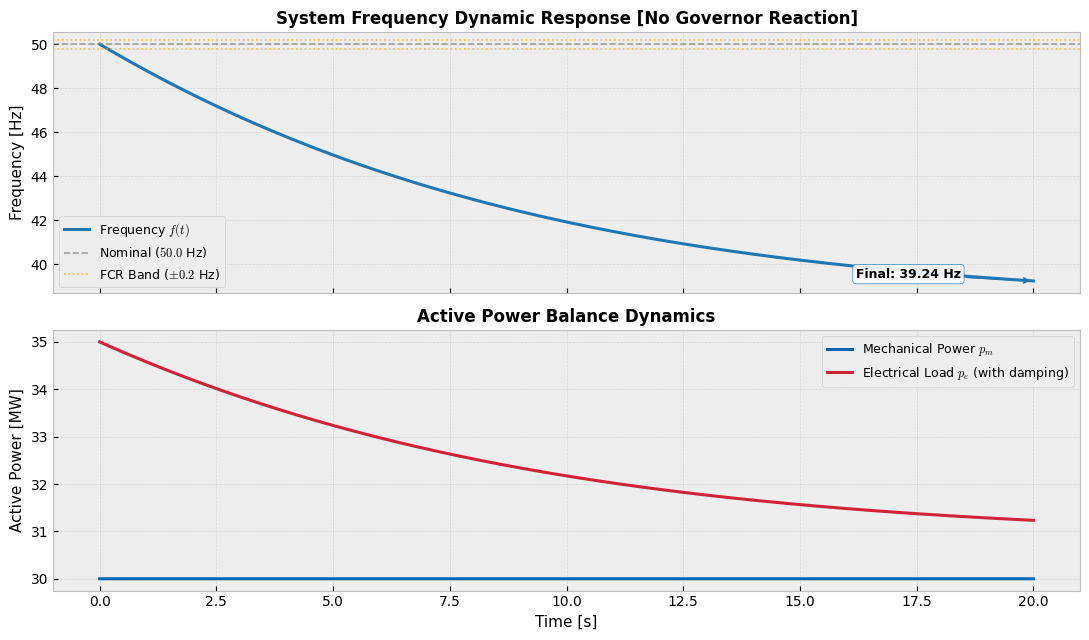

In [9]:
params = init_params()
params["droop"] = 1.0e6  # Artificially cancel governor action
init_conditions = dict(init_f=50.0, init_pm=30.0e6)

run_sim(params, init_conditions, title_suffix="[No Governor Reaction]")


### Case 2: Low-Inertia Grid ($J / 10$) without Droop
- **Setup:** Inertia divided by 10 ($J \to J/10$), representing an inverter-dominated power system with low synchronous inertia.
- **Physical Observation:** Notice the extreme initial Rate of Change of Frequency (RoCoF). The frequency plunges vertically, diving below $48.0\text{ Hz}$ in just 1 second! This shows why TSOs mandate minimum inertia or synthetic/virtual inertia from batteries.


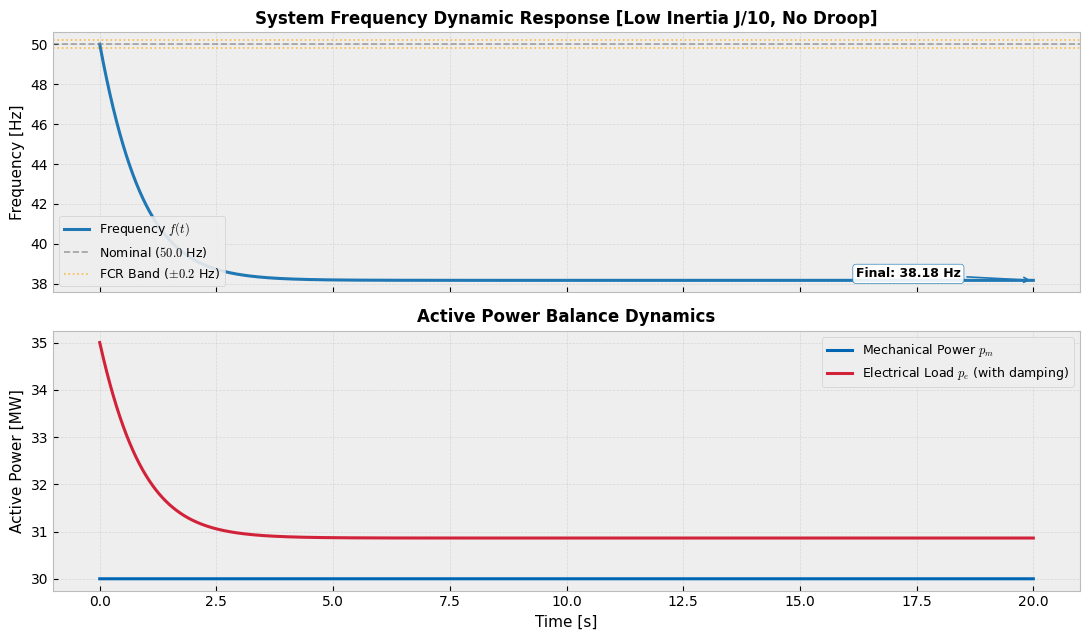

In [12]:
params = init_params()
params["J"] = params["J"] / 10.0
params["droop"] = 1.0e6
init_conditions = dict(init_f=50.0, init_pm=30.0e6)

run_sim(params, init_conditions, title_suffix="[Low Inertia J/10, No Droop]")


### Case 3: Zero Mechanical Damping ($D_g = 0$)
- **Setup:** Generator frictional and mechanical damping set to zero.
- **Physical Observation:** Without natural rotational damping, the deceleration is purely unmitigated.


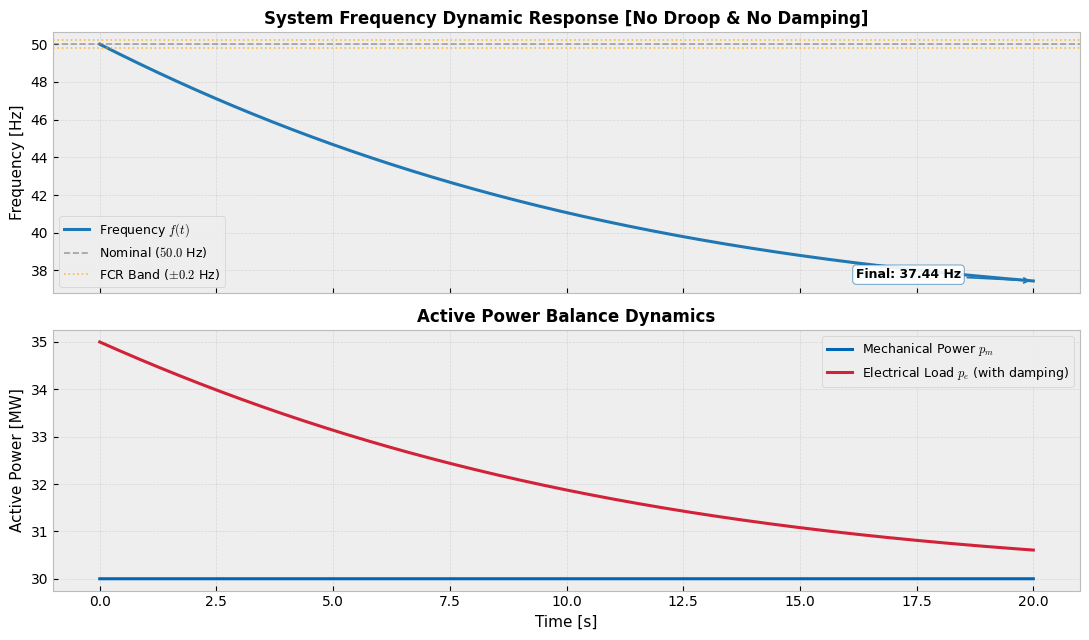

In [13]:
params = init_params()
params["droop"] = 1.0e6
params["Dg"] = 0.0
init_conditions = dict(init_f=50.0, init_pm=30.0e6)

run_sim(params, init_conditions, title_suffix="[No Droop & No Damping]")


### Case 4: Primary Frequency Control with Standard 4% Droop ($\sigma = 0.04$)
- **Governor setting:** Standard European droop ($\sigma = 4\%$).
- **Physical Observation:** As frequency drops, the governor detects $\Delta f < 0$ and opens the turbine valve. $p_m$ ramps up following servomotor delay $T_{sm} = 1.5\text{ s}$. 
- The frequency hits a Nadir ($f_{\min} \approx 49.79\text{ Hz}$) and stabilizes at $f_{\text{ss}} \approx 49.84\text{ Hz}$ within the $\pm 0.2\text{ Hz}$ FCR band.
- **Key takeaway:** A non-zero steady-state offset ($\Delta f_{\text{ss}} \neq 0$) is mandatory for proportional droop control!


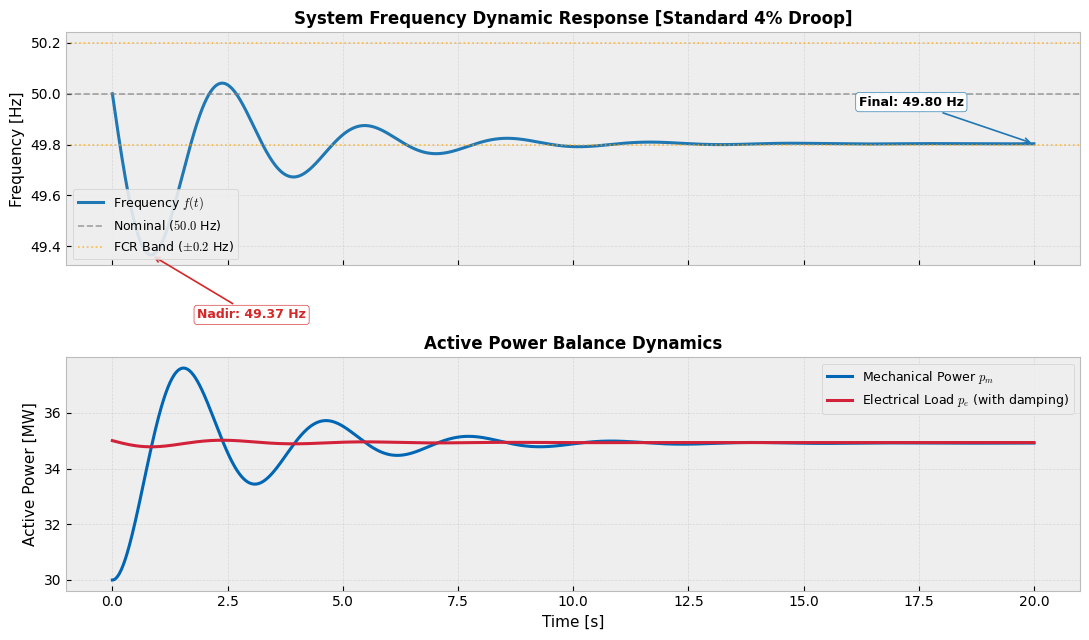

In [10]:
params = init_params()
init_conditions = dict(init_f=50.0, init_pm=30.0e6)

run_sim(params, init_conditions, title_suffix="[Standard 4% Droop]")


### Case 5: Lighter Droop ($\sigma = 8\%$)
- **Governor setting:** $\sigma$ increased to $0.08$ (less aggressive governor).
- **Physical Observation:** Because the slope is flatter, the generator injects less power per Hz of frequency deviation. 
- The steady-state frequency drops lower ($f_{\text{ss}} \approx 49.70\text{ Hz}$), resulting in a roughly double steady-state frequency error.


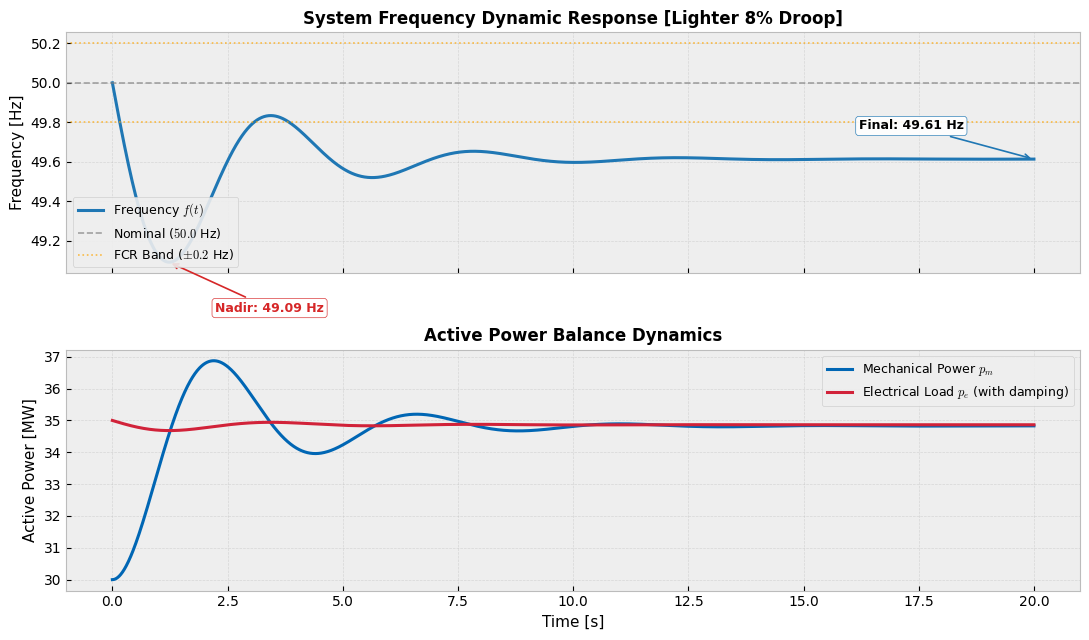

In [11]:
params = init_params()
params["droop"] = 0.08
init_conditions = dict(init_f=50.0, init_pm=30.0e6)

run_sim(params, init_conditions, title_suffix="[Lighter 8% Droop]")


### Case 6: Generator Headroom Exhaustion — Saturation at $P_{\max}$
- **Setup:** Generator starts near capacity at $P_m^o = 42\text{ MW}$. Load jumps to $49\text{ MW}$.
- **Physical Observation:** The governor ramps up mechanical power, but hits the hard rating ceiling $P_{\max} = 50\text{ MW}$. Once clamped, the generator cannot supply the remaining $49 - 50 = -1\text{ MW}$ deficit (when accounting for load damping). The system enters an unarrested decline, illustrating the severe risk of reserve exhaustion!


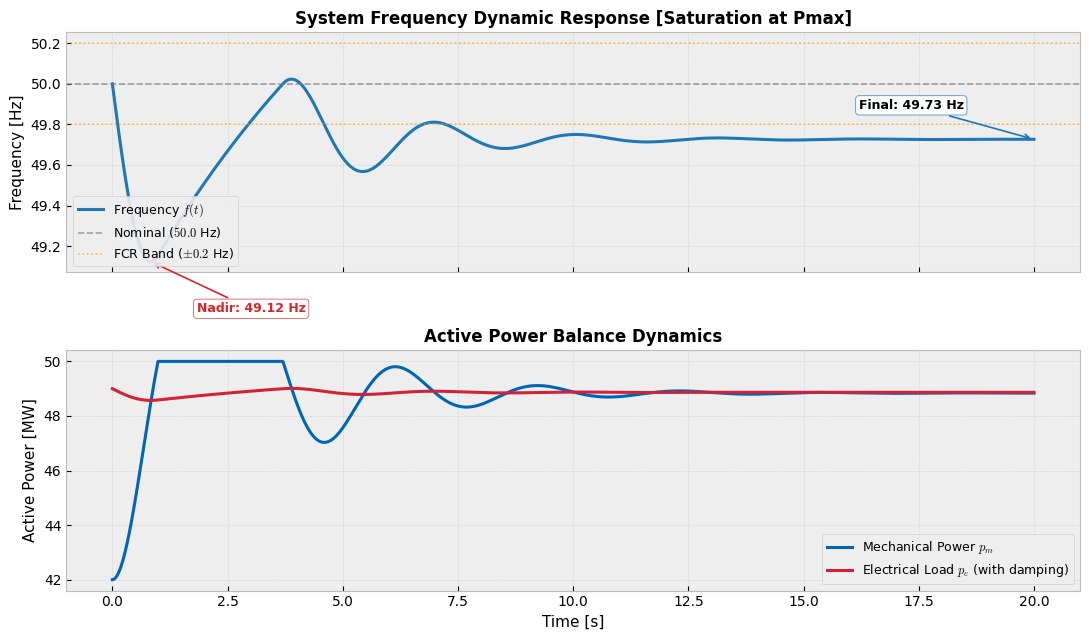

In [14]:
Pm0 = 42.0e6
params = init_params()
params["Pe0"] = 49.0e6
params["Pm0"] = Pm0
init_conditions = dict(init_f=50.0, init_pm=Pm0)

run_sim(params, init_conditions, title_suffix="[Saturation at Pmax]")


### Case 7: Load Drop and Downward Regulation ($P_{\min}$)
- **Setup:** Initial power $6\text{ MW}$, load drops suddenly to $2\text{ MW}$ (power surplus).
- **Physical Observation:** Overfrequency develops ($\Delta f > 0$), and the governor curtails mechanical power down towards $2\text{ MW}$, stabilizing safely above $P_{\min} = 0\text{ MW}$.


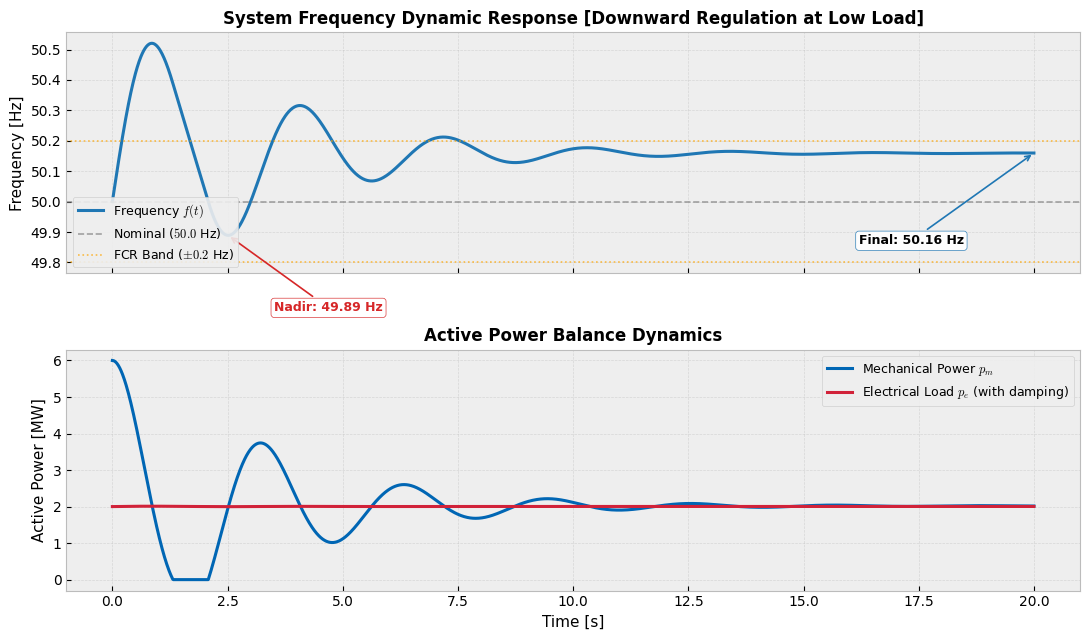

In [15]:
Pm0 = 6.0e6
params = init_params()
params["Pe0"] = 2.0e6
params["Pm0"] = Pm0
init_conditions = dict(init_f=50.0, init_pm=Pm0)

run_sim(params, init_conditions, title_suffix="[Downward Regulation at Low Load]")


### Case 8: Renewable PV Surge (+30 MW) Without Curtailment
- **Setup:** A sudden surge of $30\text{ MW}$ solar PV generation on top of existing generation.
- **Physical Observation:** Massive generation surplus pushes frequency above $51.0\text{ Hz}$, well beyond the statutory operating range.


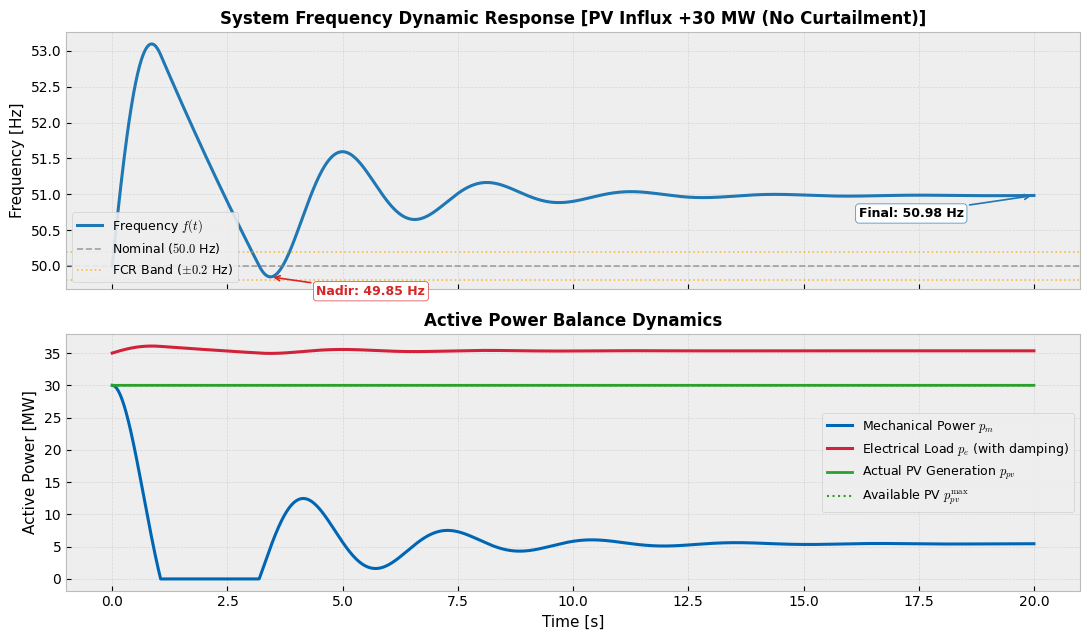

In [16]:
params = init_params()
params["Ppv0"] = 30.0e6
init_conditions = dict(init_f=50.0, init_pm=30.0e6)

run_sim(params, init_conditions, title_suffix="[PV Influx +30 MW (No Curtailment)]")


### Case 9: Inverter Overfrequency Protection — Active PV Curtailment (LFSM-O)
- **Setup:** Grid Code LFSM-O enabled (`curtail_PV=True`). When $f > 50.5\text{ Hz}$, PV plants automatically curtail active power.
- **Physical Observation:** As frequency exceeds $50.5\text{ Hz}$, PV inverters curtail active output along the green curve. This limits the overfrequency peak and safely stabilizes the system!


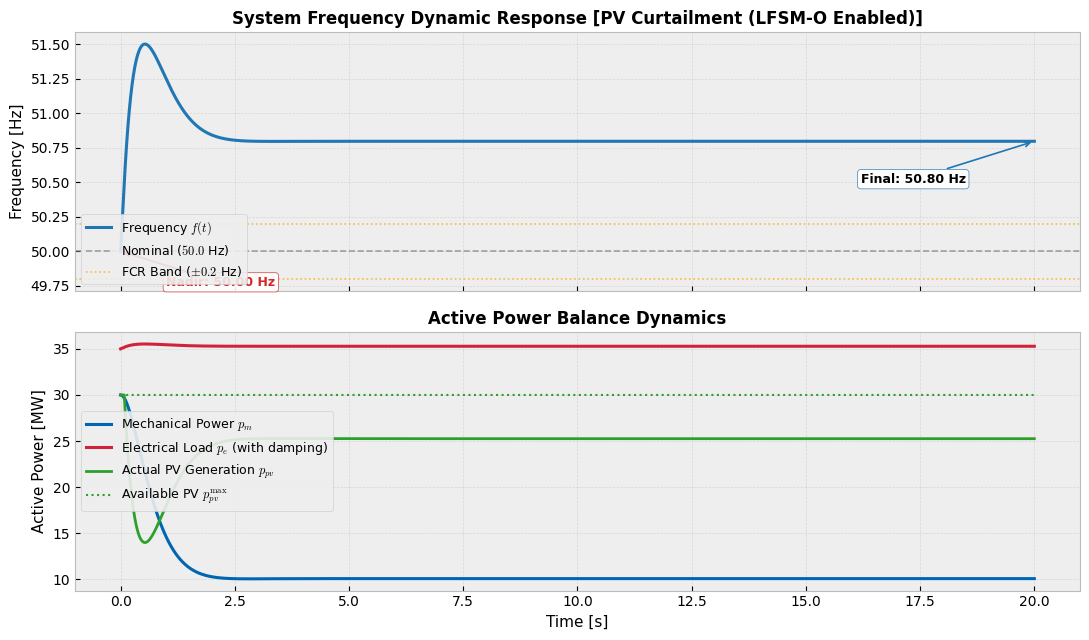

In [17]:
params = init_params()
params["Ppv0"] = 30.0e6
init_conditions = dict(init_f=50.0, init_pm=30.0e6)

run_sim(params, init_conditions, curtail_PV=True, title_suffix="[PV Curtailment (LFSM-O Enabled)]")


### Case 10: Generator Redispatch & Secondary Control Action
- **Setup:** Anticipating the $30\text{ MW}$ PV injection, the centralized operator redispatches the synchronous generator down from $30\text{ MW}$ to $10\text{ MW}$ (the operational function of secondary control / AGC).
- **Physical Observation:** Total power ($P_m + P_{pv} = 10 + 30 = 40\text{ MW}$) matches total load, restoring nominal frequency ($50.0\text{ Hz}$) with zero steady-state error!


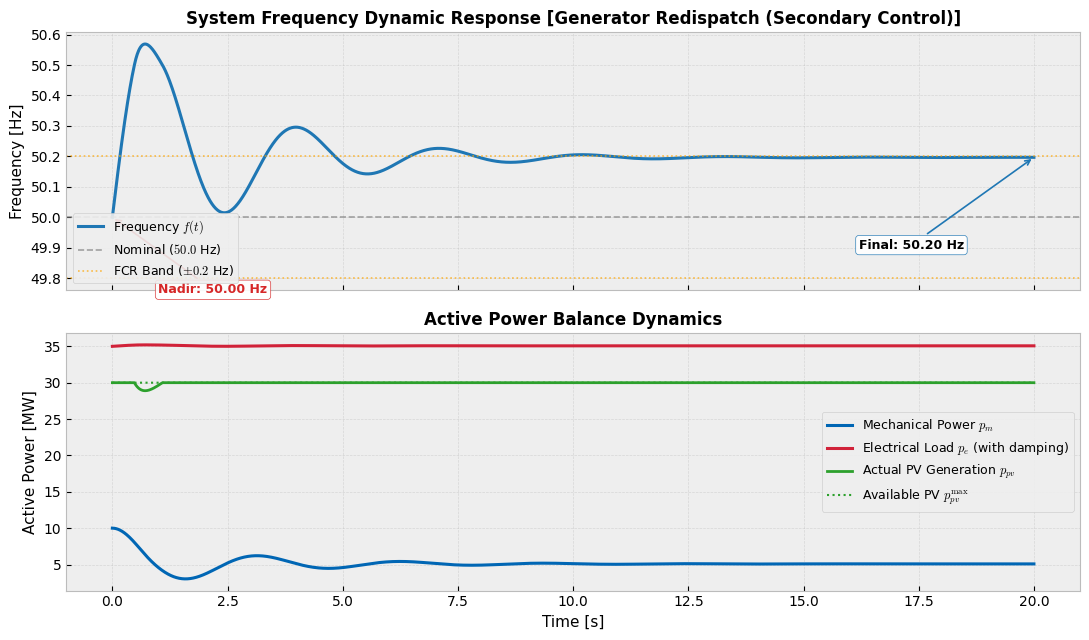

In [18]:
params = init_params()
Pm0 = 10.0e6
params["Ppv0"] = 30.0e6
params["Pm0"] = Pm0
init_conditions = dict(init_f=50.0, init_pm=Pm0)

run_sim(params, init_conditions, curtail_PV=True, title_suffix="[Generator Redispatch (Secondary Control)]")
